# Task 5: Decision Trees and Random Forests

**AI & ML Internship – Elevate Labs**

**Objective:** Build and evaluate Decision Tree and Random Forest models.

**Dataset:** Heart Disease Dataset (Kaggle).

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
from google.colab import files
uploaded = files.upload()

Saving heart.csv to heart.csv


In [3]:
df = pd.read_csv("heart.csv")
df.head()

,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1025, 14)

Column Names:
['age', 'gender', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   gender    1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nHeart Disease Distribution:")
df['target'].value_counts()

Missing Values:
age         0
gender      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Records: 723

Heart Disease Distribution:


,count
target,
1,526
0,499


In [7]:
# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Verify duplicate removal
print("Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

# Check updated target distribution
print("\nUpdated Target Distribution:")
print(df['target'].value_counts())

Shape: (302, 14)
Remaining Duplicates: 0

Updated Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [8]:
# Check unique values in categorical columns
categorical_columns = [
    'gender', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].unique()))


gender:
[np.int64(0), np.int64(1)]

cp:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

fbs:
[np.int64(0), np.int64(1)]

restecg:
[np.int64(0), np.int64(1), np.int64(2)]

exang:
[np.int64(0), np.int64(1)]

slope:
[np.int64(0), np.int64(1), np.int64(2)]

ca:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

thal:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [9]:
# Separate input features and target
X = df.drop('target', axis=1)
y = df['target']

# Identify categorical columns
categorical_columns = [
    'gender', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

# Apply One-Hot Encoding
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Display encoded features
print("Encoded Dataset Shape:", X.shape)
print("\nEncoded Column Names:")
print(X.columns.tolist())

Encoded Dataset Shape: (302, 22)

Encoded Column Names:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'gender_1', 'cp_1', 'cp_2', 'cp_3', 'fbs_1', 'restecg_1', 'restecg_2', 'exang_1', 'slope_1', 'slope_2', 'ca_1', 'ca_2', 'ca_3', 'ca_4', 'thal_1', 'thal_2', 'thal_3']


In [10]:
# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (241, 22)
Testing Features Shape: (61, 22)
Training Target Shape: (241,)
Testing Target Shape: (61,)


In [12]:
# Create Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)


DecisionTreeClassifier(random_state=42)

In [13]:
# Predict using testing data
y_pred_dt = dt_model.predict(X_test)

# Display actual and predicted values
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_dt[:10])

Actual Values: [0 0 0 0 0 0 1 0 1 0]
Predicted Values: [0 1 0 1 1 1 1 0 1 0]


In [14]:
# Calculate Decision Tree accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Accuracy (%):", dt_accuracy * 100)

Decision Tree Accuracy: 0.6557377049180327
Decision Tree Accuracy (%): 65.57377049180327


In [15]:
# Predict on training data
y_train_pred_dt = dt_model.predict(X_train)

# Calculate training accuracy
train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)

print("Training Accuracy:", train_accuracy_dt * 100)
print("Testing Accuracy:", dt_accuracy * 100)

Training Accuracy: 100.0
Testing Accuracy: 65.57377049180327


In [16]:
# Test different maximum tree depths
depths = [2, 3, 4, 5, 10, None]

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    print(
        f"Depth: {depth}, "
        f"Training Accuracy: {train_acc * 100:.2f}%, "
        f"Testing Accuracy: {test_acc * 100:.2f}%"
    )

Depth: 2, Training Accuracy: 77.59%, Testing Accuracy: 72.13%
Depth: 3, Training Accuracy: 80.91%, Testing Accuracy: 70.49%
Depth: 4, Training Accuracy: 86.72%, Testing Accuracy: 72.13%
Depth: 5, Training Accuracy: 91.70%, Testing Accuracy: 67.21%
Depth: 10, Training Accuracy: 100.00%, Testing Accuracy: 65.57%
Depth: None, Training Accuracy: 100.00%, Testing Accuracy: 65.57%


In [17]:
import graphviz

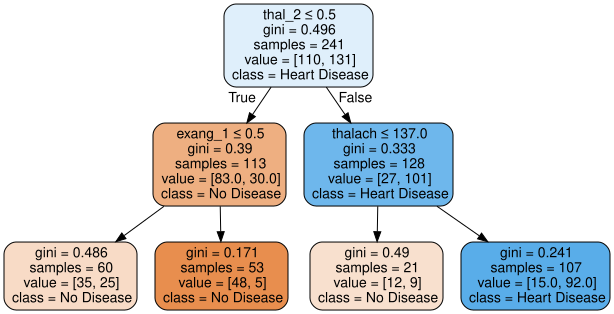

In [18]:
# Create Decision Tree with maximum depth 2
dt_model_depth2 = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Train the model
dt_model_depth2.fit(X_train, y_train)

# Visualize the Decision Tree
import graphviz
from sklearn.tree import export_graphviz

dot_data = export_graphviz(
    dt_model_depth2,
    out_file=None,
    feature_names=X.columns,
    class_names=['No Disease', 'Heart Disease'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)
graph

In [20]:
# Create Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

In [21]:
# Make predictions using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Display actual and predicted values
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_rf[:10])

Actual Values: [0 0 0 0 0 0 1 0 1 0]
Predicted Values: [0 1 0 0 1 0 1 0 1 0]


In [22]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 81.9672131147541 %


In [23]:
# Calculate training accuracy
rf_train_accuracy = accuracy_score(
    y_train, rf_model.predict(X_train)
)

# Calculate testing accuracy
rf_test_accuracy = accuracy_score(
    y_test, y_pred_rf
)

print("Random Forest Training Accuracy:",
      rf_train_accuracy * 100, "%")

print("Random Forest Testing Accuracy:",
      rf_test_accuracy * 100, "%")

Random Forest Training Accuracy: 100.0 %
Random Forest Testing Accuracy: 81.9672131147541 %


In [24]:
# Calculate feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

      Feature  Importance
3     thalach    0.127634
4     oldpeak    0.111854
20     thal_2    0.087749
0         age    0.087607
2        chol    0.083082
21     thal_3    0.078182
1    trestbps    0.075382
12    exang_1    0.068799
7        cp_2    0.047578
5    gender_1    0.039732
14    slope_2    0.028108
15       ca_1    0.026745
16       ca_2    0.024226
8        cp_3    0.023033
10  restecg_1    0.020492
13    slope_1    0.018882
6        cp_1    0.015116
17       ca_3    0.014352
9       fbs_1    0.012701
19     thal_1    0.006488
18       ca_4    0.001382
11  restecg_2    0.000875


In [25]:
# Cross-validation for Decision Tree
dt_cv_scores = cross_val_score(
    dt_model_depth2,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

# Cross-validation for Random Forest
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

# Display results
print("Decision Tree CV Scores:", dt_cv_scores)
print("Decision Tree Mean CV Accuracy:",
      dt_cv_scores.mean() * 100, "%")

print("\nRandom Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean CV Accuracy:",
      rf_cv_scores.mean() * 100, "%")

Decision Tree CV Scores: [0.79591837 0.60416667 0.66666667 0.625      0.70833333]
Decision Tree Mean CV Accuracy: 68.00170068027211 %

Random Forest CV Scores: [0.81632653 0.72916667 0.75       0.79166667 0.77083333]
Random Forest Mean CV Accuracy: 77.15986394557824 %


In [26]:
# Create model comparison
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Training Accuracy': [
        accuracy_score(y_train, dt_model_depth2.predict(X_train)) * 100,
        rf_train_accuracy * 100
    ],
    'Testing Accuracy': [
        accuracy_score(y_test, dt_model_depth2.predict(X_test)) * 100,
        rf_test_accuracy * 100
    ],
    'Cross-Validation Accuracy': [
        dt_cv_scores.mean() * 100,
        rf_cv_scores.mean() * 100
    ]
})

print(comparison.round(2))


           Model  Training Accuracy  Testing Accuracy  \
0  Decision Tree              77.59             72.13   
1  Random Forest             100.00             81.97   

   Cross-Validation Accuracy  
0                      68.00  
1                      77.16  


In [27]:
# Confusion Matrix
print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Classification Report
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Confusion Matrix:
[[23  5]
 [ 6 27]]

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.81        28
           1       0.84      0.82      0.83        33

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



In [28]:
# Save the cleaned dataset
df.to_csv('Heart_Disease_Cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
